# Phase 2: Exploratory Data Analysis (EDA)
**Project:** Smart Campus Energy Analytics and Forecasting System  |  **Author:** Santanu Mondal

**Campus:** site `Fox` from the Building Data Genome Project 2 (BDG2), 131 buildings, hourly electricity, 2016-2017.
This is open data, not Adamas University data.

**Questions this notebook answers**
1. How complete and clean is the data?
2. When does the campus use energy (hour, weekday, month)?
3. How does outdoor temperature affect the load?
4. Which buildings and building types use the most, and who is inefficient?
5. What did the BDG2 authors remove when they made the *cleaned* file (raw vs cleaned)? This decides how we validate anomaly detection in Phase 4.

> Run all cells top to bottom. After each plot, write 1 or 2 lines in the **Observation** cell from what you actually see.

## 1. Setup

In [1]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

%matplotlib inline
plt.rcParams['figure.figsize'] = (11, 4)
plt.rcParams['axes.grid'] = True
plt.rcParams['grid.alpha'] = 0.3

ROOT = Path.cwd().parent if Path.cwd().name == 'notebooks' else Path.cwd()
PROC = ROOT / 'data' / 'processed'
RAW = ROOT / 'data' / 'raw' / 'bdg2'
CAMPUS_SITE = 'Fox'
for p in [PROC / 'campus_long.parquet', PROC / 'campus_total.parquet', PROC / 'buildings_meta.csv',
          RAW / 'electricity.csv', RAW / 'electricity_cleaned.csv', RAW / 'weather.csv']:
    print(('OK      ' if p.exists() else 'MISSING ') + str(p.relative_to(ROOT)))

OK      data\processed\campus_long.parquet
OK      data\processed\campus_total.parquet
OK      data\processed\buildings_meta.csv
OK      data\raw\bdg2\electricity.csv
OK      data\raw\bdg2\electricity_cleaned.csv
OK      data\raw\bdg2\weather.csv


## 2. Load data and check columns

In [2]:
long_df = pd.read_parquet(PROC / 'campus_long.parquet')
total = pd.read_parquet(PROC / 'campus_total.parquet')
meta = pd.read_csv(PROC / 'buildings_meta.csv')

long_df['timestamp'] = pd.to_datetime(long_df['timestamp'])
total['timestamp'] = pd.to_datetime(total['timestamp'])

print('campus_long :', long_df.shape)
print('campus_total:', total.shape)
print('meta        :', meta.shape)
print()
print('campus_long columns:', list(long_df.columns))
print('meta columns       :', list(meta.columns))

def pick(cols, name):
    for c in cols:
        if c.lower() == name:
            return c
    raise KeyError(f"column '{name}' not found, available: {list(cols)}")

USAGE = pick(meta.columns, 'primaryspaceusage')
SQM = pick(meta.columns, 'sqm')
assert 'building_id' in meta.columns and 'building_id' in long_df.columns
print('\nusing usage column =', USAGE, '| area column =', SQM)
long_df.head()

campus_long : (2298264, 25)
campus_total: (17544, 3)
meta        : (131, 7)

campus_long columns: ['timestamp', 'building_id', 'kwh', 'site_id', 'primaryspaceusage', 'sub_primaryspaceusage', 'sqm', 'yearbuilt', 'numberoffloors', 'airTemperature', 'cloudCoverage', 'dewTemperature', 'precipDepth1HR', 'precipDepth6HR', 'seaLvlPressure', 'windDirection', 'windSpeed', 'airTemperature_gap_flag', 'cloudCoverage_gap_flag', 'dewTemperature_gap_flag', 'precipDepth1HR_gap_flag', 'precipDepth6HR_gap_flag', 'seaLvlPressure_gap_flag', 'windDirection_gap_flag', 'windSpeed_gap_flag']
meta columns       : ['building_id', 'site_id', 'primaryspaceusage', 'sub_primaryspaceusage', 'sqm', 'yearbuilt', 'numberoffloors']

using usage column = primaryspaceusage | area column = sqm


,timestamp,building_id,kwh,site_id,primaryspaceusage,sub_primaryspaceusage,sqm,yearbuilt,numberoffloors,airTemperature,...,windDirection,windSpeed,airTemperature_gap_flag,cloudCoverage_gap_flag,dewTemperature_gap_flag,precipDepth1HR_gap_flag,precipDepth6HR_gap_flag,seaLvlPressure_gap_flag,windDirection_gap_flag,windSpeed_gap_flag
0,2016-01-01 00:00:00,Fox_lodging_Stephen,58.520000,Fox,Lodging/residential,Dormitory,8019.7,1956.0,NaN,7.2,...,0.0,0.0,0,0,0,0,1,0,0,0
1,2016-01-01 01:00:00,Fox_lodging_Stephen,60.169998,Fox,Lodging/residential,Dormitory,8019.7,1956.0,NaN,7.2,...,50.0,1.5,0,0,0,0,1,0,0,0
2,2016-01-01 02:00:00,Fox_lodging_Stephen,59.349998,Fox,Lodging/residential,Dormitory,8019.7,1956.0,NaN,6.1,...,0.0,0.0,0,0,0,0,1,0,0,0
3,2016-01-01 03:00:00,Fox_lodging_Stephen,59.439999,Fox,Lodging/residential,Dormitory,8019.7,1956.0,NaN,5.0,...,0.0,0.0,0,0,0,0,1,0,0,0
4,2016-01-01 04:00:00,Fox_lodging_Stephen,58.230000,Fox,Lodging/residential,Dormitory,8019.7,1956.0,NaN,4.4,...,0.0,0.0,0,0,0,0,1,0,0,0


## 3. Data quality

In [3]:
n_buildings = long_df['building_id'].nunique()
n_hours = long_df['timestamp'].nunique()
print(f'buildings: {n_buildings} | hours: {n_hours} | range: {long_df.timestamp.min()} to {long_df.timestamp.max()}')
print(f"kwh missing: {long_df['kwh'].isna().mean()*100:.2f}% | zeros: {(long_df['kwh']==0).mean()*100:.3f}% | negatives: {(long_df['kwh']<0).sum()}")
print()
long_df['kwh'].describe().round(2)

buildings: 131 | hours: 17544 | range: 2016-01-01 00:00:00 to 2017-12-31 23:00:00
kwh missing: 0.40% | zeros: 0.000% | negatives: 0



count    2288993.00
mean         152.10
std          261.49
min            0.01
25%           30.69
50%           86.81
75%          170.76
max         3193.57
Name: kwh, dtype: float64

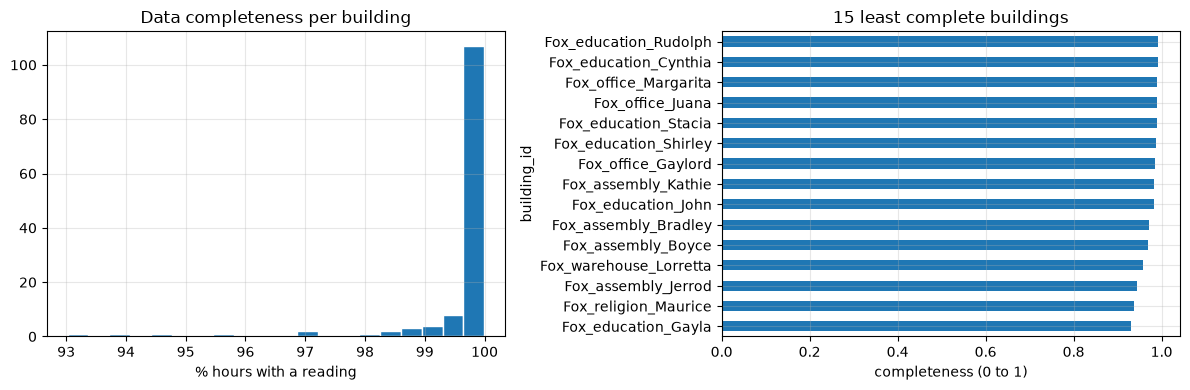

buildings below 95% complete: 3


In [4]:
comp = long_df['kwh'].notna().groupby(long_df['building_id'], observed=True).mean().sort_values()
fig, ax = plt.subplots(1, 2, figsize=(12, 4))
ax[0].hist(comp * 100, bins=20, edgecolor='white')
ax[0].set_title('Data completeness per building'); ax[0].set_xlabel('% hours with a reading')
comp.head(15).plot.barh(ax=ax[1], title='15 least complete buildings')
ax[1].set_xlabel('completeness (0 to 1)')
plt.tight_layout(); plt.show()
print('buildings below 95% complete:', int((comp < 0.95).sum()))

**Observation:** (write after running: how complete is the data, and are any buildings clearly worse?)

campus_total NaN hours: 7
                timestamp  kwh  n_reporting
1984  2016-03-23 16:00:00  NaN            1
3098  2016-05-09 02:00:00  NaN           90
3434  2016-05-23 02:00:00  NaN           53
11148 2017-04-09 12:00:00  NaN           31
17453 2017-12-28 05:00:00  NaN           96
17454 2017-12-28 06:00:00  NaN           95
17455 2017-12-28 07:00:00  NaN           97

buildings reporting per hour: min 1 | median 131 | max 131


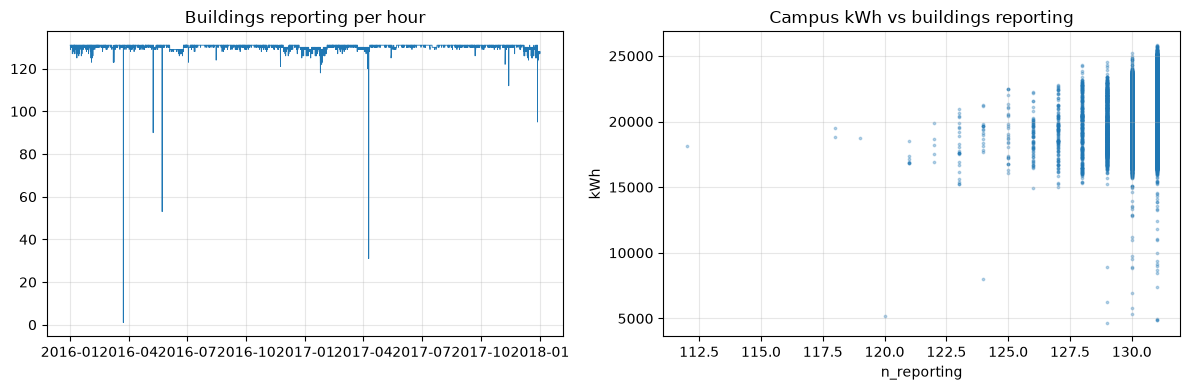

hours with fewer than all buildings reporting: 5870 (33.5%)
median campus kWh, all reporting vs not: 19654 vs 19322


In [5]:
nan_hours = total[total['kwh'].isna()]
print('campus_total NaN hours:', len(nan_hours))
print(nan_hours.head(10).to_string())
print()
full = int(total['n_reporting'].max())
print('buildings reporting per hour: min', int(total['n_reporting'].min()), '| median', int(total['n_reporting'].median()), '| max', full)

fig, ax = plt.subplots(1, 2, figsize=(12, 4))
ax[0].plot(total['timestamp'], total['n_reporting'], lw=0.6)
ax[0].set_title('Buildings reporting per hour')
ok = total.dropna(subset=['kwh'])
ax[1].scatter(ok['n_reporting'], ok['kwh'], s=3, alpha=0.3)
ax[1].set_title('Campus kWh vs buildings reporting'); ax[1].set_xlabel('n_reporting'); ax[1].set_ylabel('kWh')
plt.tight_layout(); plt.show()
low = ok[ok['n_reporting'] < full]
print('hours with fewer than all buildings reporting:', len(low), f'({len(low)/len(ok)*100:.1f}%)')
print('median campus kWh, all reporting vs not:', round(ok[ok.n_reporting == full]['kwh'].median()), 'vs', round(low['kwh'].median()) if len(low) else 'n/a')

**Observation:** (do dips in campus kWh line up with fewer buildings reporting? If yes, those dips are data gaps, not real low usage, and Phase 5 must handle them.)

## 4. When does the campus use energy?

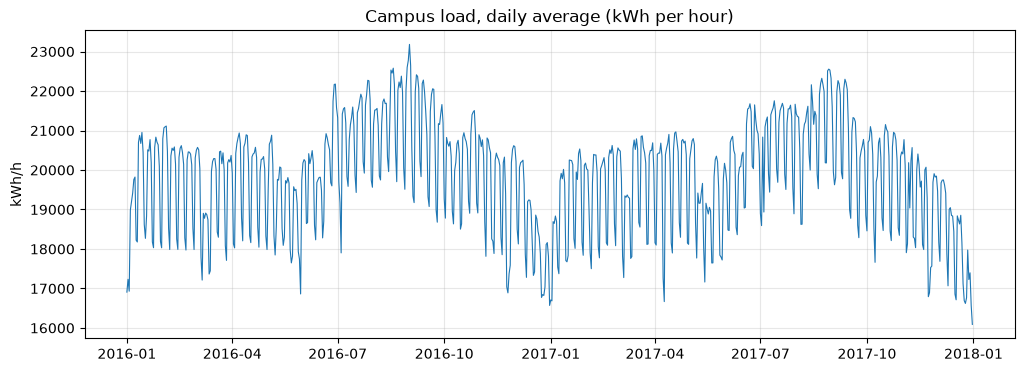

In [6]:
ts = total.set_index('timestamp')['kwh']
daily = ts.resample('D').mean()
fig, ax = plt.subplots(figsize=(12, 4))
ax.plot(daily.index, daily.values, lw=0.8)
ax.set_title('Campus load, daily average (kWh per hour)'); ax.set_ylabel('kWh/h')
plt.show()

**Observation:** (write: seasonal pattern, holiday dips, any odd jumps or flat stretches?)

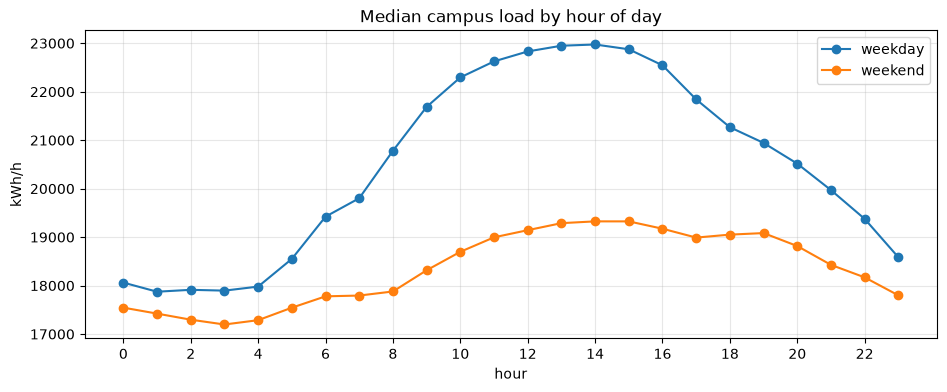

weekday peak hour: 14
weekend mean is -9.7% vs weekday mean


In [7]:
total['hour'] = total['timestamp'].dt.hour
total['dow'] = total['timestamp'].dt.day_of_week
total['month'] = total['timestamp'].dt.month
total['year'] = total['timestamp'].dt.year
total['is_weekend'] = total['dow'] >= 5

prof = total.groupby(['hour', 'is_weekend'])['kwh'].median().unstack()
prof.columns = ['weekday', 'weekend']
ax = prof.plot(marker='o', title='Median campus load by hour of day', figsize=(11, 4))
ax.set_ylabel('kWh/h'); ax.set_xticks(range(0, 24, 2))
plt.show()
peak_hour = int(prof['weekday'].idxmax())
wk = total.groupby('is_weekend')['kwh'].mean()
print('weekday peak hour:', peak_hour)
print(f'weekend mean is {(wk[True]/wk[False]-1)*100:.1f}% vs weekday mean')

**Observation:** (write: when is the peak, how big is the day/night swing, how different is the weekend?)

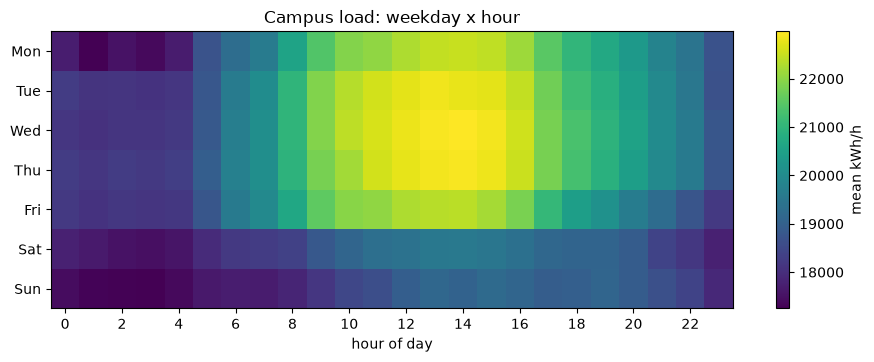

In [8]:
heat = total.pivot_table(index='dow', columns='hour', values='kwh', aggfunc='mean')
fig, ax = plt.subplots(figsize=(11, 3.6))
im = ax.imshow(heat.values, aspect='auto', cmap='viridis')
ax.set_yticks(range(7)); ax.set_yticklabels(['Mon','Tue','Wed','Thu','Fri','Sat','Sun'])
ax.set_xticks(range(0, 24, 2)); ax.set_xlabel('hour of day'); ax.grid(False)
plt.colorbar(im, label='mean kWh/h'); ax.set_title('Campus load: weekday x hour')
plt.show()

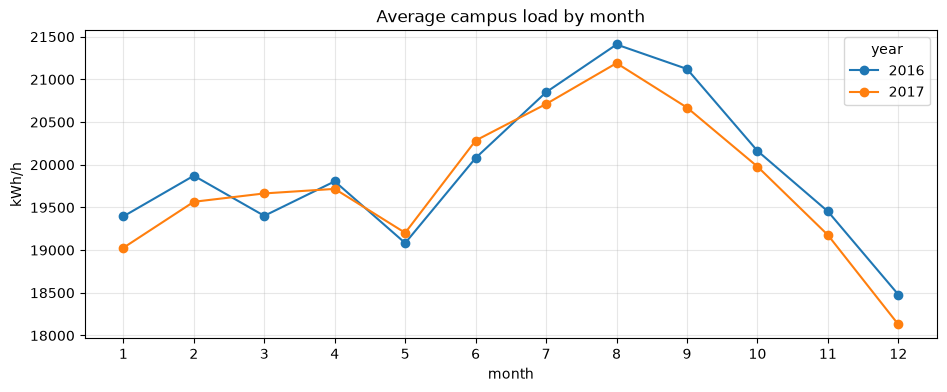

busiest month (avg of both years): 8 | quietest: 12


In [9]:
monthly = total.pivot_table(index='month', columns='year', values='kwh', aggfunc='mean')
ax = monthly.plot(marker='o', title='Average campus load by month', figsize=(11, 4))
ax.set_xticks(range(1, 13)); ax.set_ylabel('kWh/h')
plt.show()
print('busiest month (avg of both years):', int(monthly.mean(axis=1).idxmax()), '| quietest:', int(monthly.mean(axis=1).idxmin()))

**Observation:** (write: is there a summer or winter peak? do 2016 and 2017 look alike?)

## 5. Weather and load

weather rows for Fox : 17543 | missing airTemperature: 1


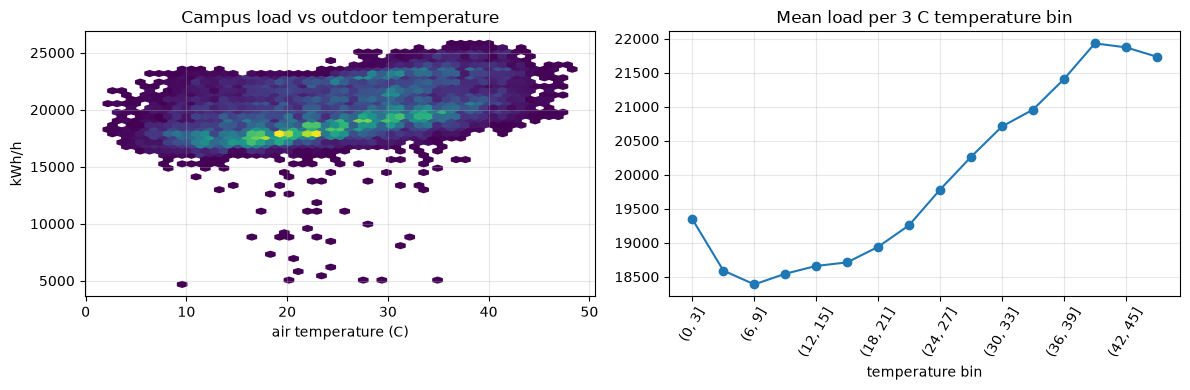

correlation load vs temperature: 0.49


In [10]:
wx = pd.read_csv(RAW / 'weather.csv')
wx['timestamp'] = pd.to_datetime(wx['timestamp'])
wx = wx[wx['site_id'] == CAMPUS_SITE]
print('weather rows for', CAMPUS_SITE, ':', len(wx), '| missing airTemperature:', int(wx['airTemperature'].isna().sum()))
tw = total.merge(wx[['timestamp', 'airTemperature']], on='timestamp', how='left').dropna(subset=['kwh', 'airTemperature'])

fig, ax = plt.subplots(1, 2, figsize=(12, 4))
ax[0].hexbin(tw['airTemperature'], tw['kwh'], gridsize=50, cmap='viridis', mincnt=1)
ax[0].set_title('Campus load vs outdoor temperature'); ax[0].set_xlabel('air temperature (C)'); ax[0].set_ylabel('kWh/h')
bins = pd.cut(tw['airTemperature'], bins=np.arange(-30, 50, 3))
tw.groupby(bins, observed=True)['kwh'].mean().plot(ax=ax[1], marker='o')
ax[1].set_title('Mean load per 3 C temperature bin'); ax[1].set_xlabel('temperature bin'); ax[1].tick_params(axis='x', rotation=60)
plt.tight_layout(); plt.show()
print('correlation load vs temperature:', round(tw['kwh'].corr(tw['airTemperature']), 3))

**Observation:** (write: does load rise with heat, with cold, or both? is the relationship strong or weak? This tells us how much weather will help the forecast.)

## 6. Buildings and building types

In [11]:
usage_map = meta.set_index('building_id')[USAGE]
sqm_map = meta.set_index('building_id')[SQM]

kwh64 = long_df['kwh'].astype('float64')
g = kwh64.groupby(long_df['building_id'], observed=True)
bt = pd.DataFrame({'total_kwh': g.sum(), 'mean_kwh_per_h': g.mean()})
bt.index = bt.index.astype(str)   # building_id is categorical in the parquet, plain strings are safer
bt['usage'] = bt.index.map(usage_map)
bt['sqm'] = bt.index.map(sqm_map)
bt['kwh_per_sqm_year'] = bt['mean_kwh_per_h'] * 8760 / bt['sqm']
bt = bt.sort_values('total_kwh', ascending=False)

u = bt.groupby('usage').agg(buildings=('total_kwh', 'size'), total_kwh=('total_kwh', 'sum'),
                            median_kwh_per_sqm_year=('kwh_per_sqm_year', 'median'))
u['share_of_campus_%'] = (u['total_kwh'] / u['total_kwh'].sum() * 100).round(1)
u = u.sort_values('total_kwh', ascending=False)
u.round(1)

,buildings,total_kwh,median_kwh_per_sqm_year,share_of_campus_%
usage,,,,
Education,57,211322376.4,139.5,60.7
Entertainment/public assembly,21,40642005.9,112.6,11.7
Office,24,38654541.4,103.4,11.1
Lodging/residential,12,27176636.6,84.2,7.8
Public services,6,14186726.0,119.2,4.1
Utility,1,8205466.4,2008.7,2.4
Parking,3,2839944.7,10.4,0.8
Food sales and service,2,2358810.0,235.7,0.7
Retail,1,1133232.2,134.8,0.3


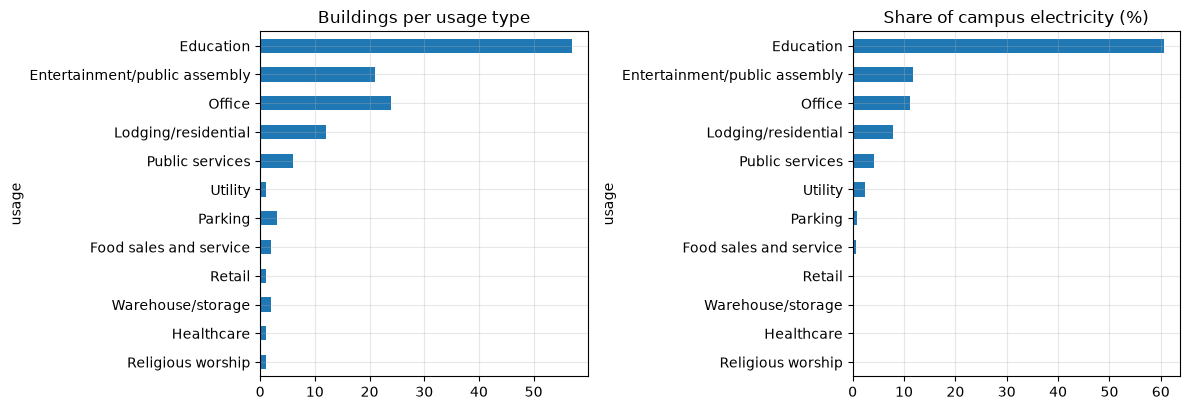

In [12]:
fig, ax = plt.subplots(1, 2, figsize=(12, 4.2))
u['buildings'].plot.barh(ax=ax[0], title='Buildings per usage type'); ax[0].invert_yaxis()
u['share_of_campus_%'].plot.barh(ax=ax[1], title='Share of campus electricity (%)'); ax[1].invert_yaxis()
plt.tight_layout(); plt.show()

**Observation:** (write: which usage types dominate by count, and which by energy? are they the same?)

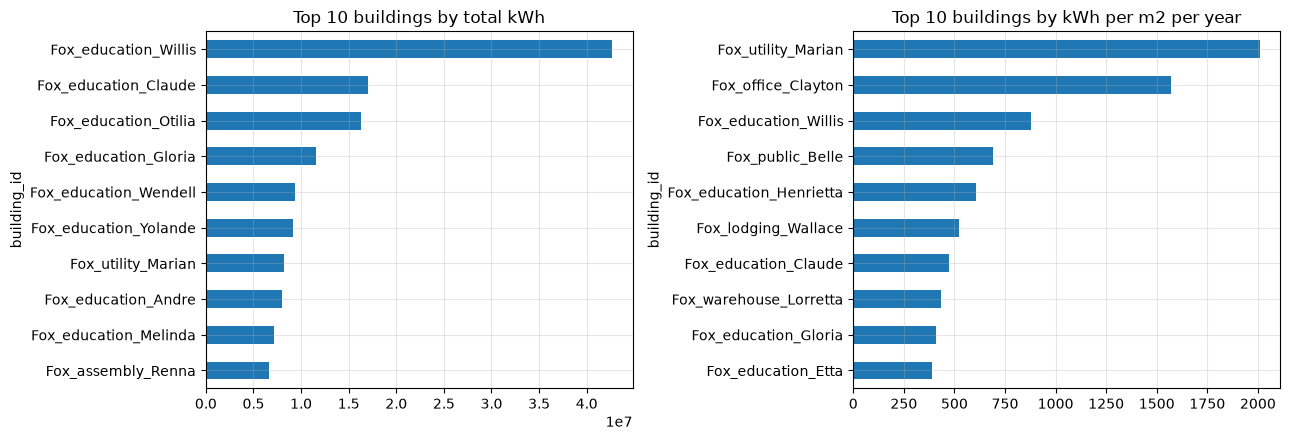

Top 10 by total kWh share of campus: 39.1%


,usage,sqm,kwh_per_sqm_year
building_id,,,
Fox_utility_Marian,Utility,2040.0,2008.7
Fox_office_Clayton,Office,488.5,1572.6
Fox_education_Willis,Education,24265.1,878.5
Fox_public_Belle,Public services,1524.6,692.9
Fox_education_Henrietta,Education,425.8,607.1
Fox_lodging_Wallace,Lodging/residential,5885.2,522.0
Fox_education_Claude,Education,17957.6,473.7
Fox_warehouse_Lorretta,Warehouse/storage,360.2,434.8
Fox_education_Gloria,Education,14087.5,410.7


In [13]:
top_total = bt.head(10)
top_eui = bt.dropna(subset=['kwh_per_sqm_year']).sort_values('kwh_per_sqm_year', ascending=False).head(10)
fig, ax = plt.subplots(1, 2, figsize=(13, 4.5))
top_total['total_kwh'].plot.barh(ax=ax[0], title='Top 10 buildings by total kWh'); ax[0].invert_yaxis()
top_eui['kwh_per_sqm_year'].plot.barh(ax=ax[1], title='Top 10 buildings by kWh per m2 per year'); ax[1].invert_yaxis()
plt.tight_layout(); plt.show()
print('Top 10 by total kWh share of campus: %.1f%%' % (top_total['total_kwh'].sum() / bt['total_kwh'].sum() * 100))
top_eui[['usage', 'sqm', 'kwh_per_sqm_year']].round(1)

**Observation:** (write: are the biggest users also the least efficient per m2? what types are the high-intensity ones?)

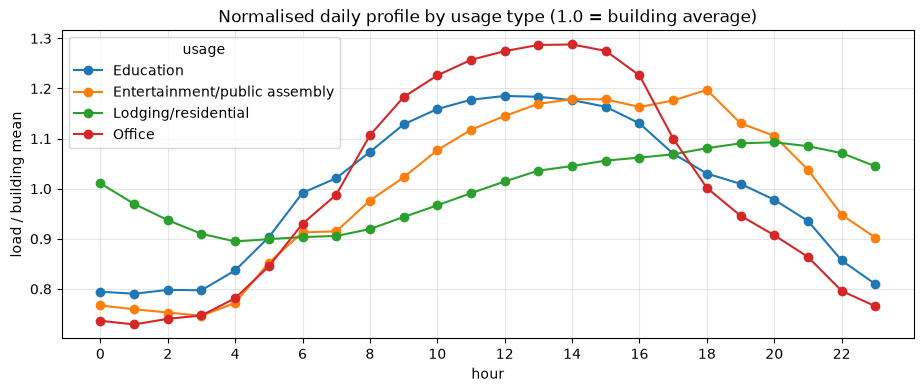

In [14]:
long_df['hour'] = long_df['timestamp'].dt.hour.astype('int8')
long_df['usage'] = long_df['building_id'].map(usage_map)
bmean = long_df.groupby('building_id', observed=True)['kwh'].transform('mean')
long_df['rel'] = long_df['kwh'] / bmean
top_types = u.index[:4]
rp = (long_df[long_df['usage'].isin(top_types)]
      .groupby(['usage', 'hour'], observed=True)['rel'].mean().unstack(0))
ax = rp.plot(marker='o', title='Normalised daily profile by usage type (1.0 = building average)', figsize=(11, 4))
ax.set_xticks(range(0, 24, 2)); ax.set_ylabel('load / building mean')
plt.show()

**Observation:** (write: do building types have different daily shapes? e.g. which ones stay high at night?)

C:\Users\Santanu Mondal\AppData\Local\Temp\ipykernel_12736\3102553280.py:6: MatplotlibDeprecationWarning: vert: bool was deprecated in Matplotlib 3.11 and will be removed in 3.13. Use orientation: {'vertical', 'horizontal'} instead.
  ax[1].boxplot(data, vert=False, tick_labels=list(big))


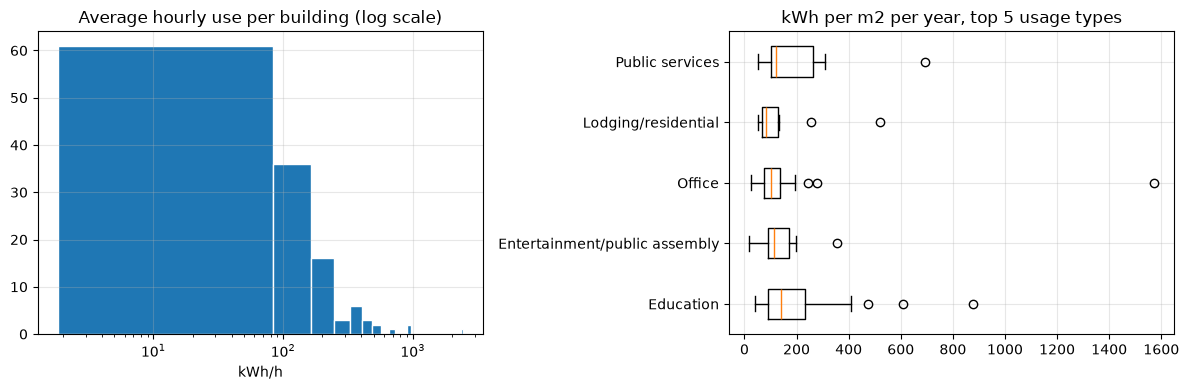

In [15]:
fig, ax = plt.subplots(1, 2, figsize=(12, 4))
ax[0].hist(bt['mean_kwh_per_h'].dropna(), bins=30, edgecolor='white')
ax[0].set_xscale('log'); ax[0].set_title('Average hourly use per building (log scale)'); ax[0].set_xlabel('kWh/h')
big = u.index[:5]
data = [bt.loc[bt['usage'] == t, 'kwh_per_sqm_year'].dropna().values for t in big]
ax[1].boxplot(data, vert=False, tick_labels=list(big))
ax[1].set_title('kWh per m2 per year, top 5 usage types')
plt.tight_layout(); plt.show()

## 7. Raw vs cleaned electricity (important for Phase 4)
`electricity.csv` is the raw data. `electricity_cleaned.csv` is the BDG2 filtered version where suspicious readings were removed.
Our processed campus data was built from the **cleaned** file. If most removed readings are faults (zeros, spikes, flat lines), they can act as *weak anomaly labels* in Phase 4. This section checks that before we rely on it.

In [16]:
blds = [str(b) for b in bt.index]
first = pd.read_csv(RAW / 'electricity.csv', nrows=0).columns[0]

def load_wide(name):
    df = pd.read_csv(RAW / name, usecols=lambda c: c == first or c in set(blds), index_col=0, parse_dates=True)
    return df.astype('float32')

raw = load_wide('electricity.csv')
cln = load_wide('electricity_cleaned.csv')
common = [c for c in blds if c in raw.columns and c in cln.columns]
raw, cln = raw[common], cln[common]
print('wide shapes:', raw.shape, cln.shape, '| buildings matched:', len(common), 'of', len(blds))

removed = raw.notna() & cln.isna()
both = raw.notna() & cln.notna()
changed = both & (raw != cln)
print(f'raw readings present: {int(raw.notna().sum().sum()):,}')
print(f'removed by cleaning (raw present, cleaned missing): {int(removed.sum().sum()):,} ({removed.sum().sum()/raw.notna().sum().sum()*100:.2f}%)')
print(f'present in both but values differ: {int(changed.sum().sum()):,}')

wide shapes: (17544, 131) (17544, 131) | buildings matched: 131 of 131
raw readings present: 2,295,586
removed by cleaning (raw present, cleaned missing): 6,593 (0.29%)
present in both but values differ: 0


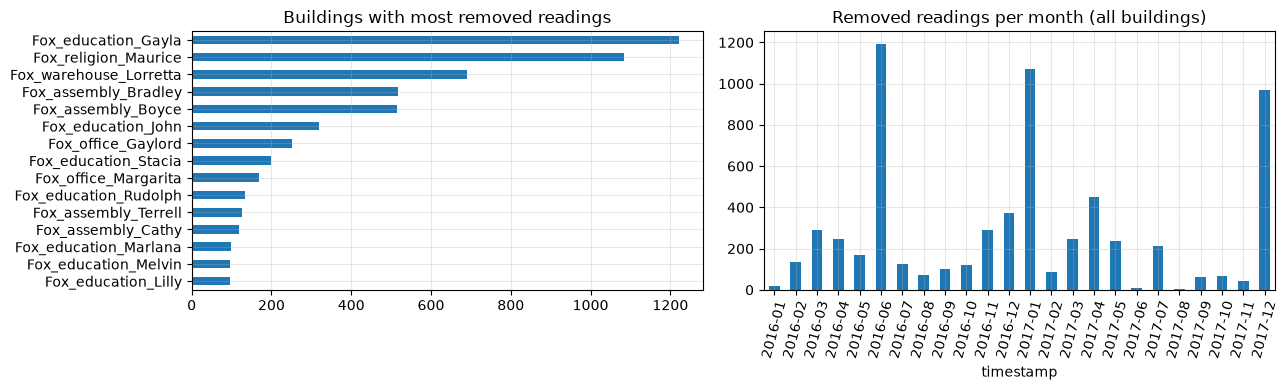

buildings with any removed readings: 127 of 131


In [17]:
rem_b = removed.sum().sort_values(ascending=False)
fig, ax = plt.subplots(1, 2, figsize=(13, 4))
rem_b.head(15).plot.barh(ax=ax[0], title='Buildings with most removed readings'); ax[0].invert_yaxis()
mo = removed.sum(axis=1).resample('MS').sum()
mo.index = mo.index.strftime('%Y-%m')
mo.plot(ax=ax[1], kind='bar', title='Removed readings per month (all buildings)')
ax[1].tick_params(axis='x', rotation=75)
plt.tight_layout(); plt.show()
print('buildings with any removed readings:', int((rem_b > 0).sum()), 'of', len(rem_b))

removed readings analysed: 6593
  exactly zero            : 100.0%
  below 10% of bldg median: 100.0%
  above 2x building median: 0.0%
  between 0.1x and 2x     : 0.0%


buildings with a flat run >= 24 h:  raw 23 | cleaned 12


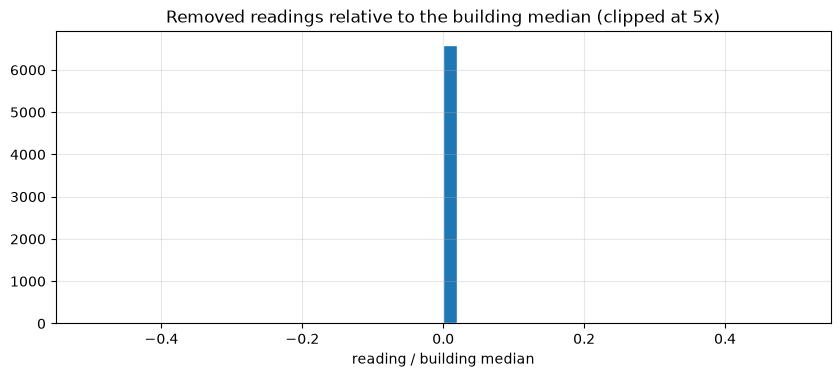

In [18]:
med = raw.median()
vals = raw.where(removed).stack().dropna()   # pandas 3 keeps NaN when stacking, so drop them
ratio = (raw.where(removed) / med).stack().dropna()
print('removed readings analysed:', len(vals))
print(f'  exactly zero            : {(vals == 0).mean()*100:.1f}%')
print(f'  below 10% of bldg median: {(ratio < 0.1).mean()*100:.1f}%')
print(f'  above 2x building median: {(ratio > 2).mean()*100:.1f}%')
print(f'  between 0.1x and 2x     : {((ratio >= 0.1) & (ratio <= 2)).mean()*100:.1f}%')

def longest_run(x):
    x = x[~np.isnan(x)]
    if len(x) < 2:
        return 0
    same = np.r_[False, x[1:] == x[:-1]]
    best = cur = 0
    for s in same:
        cur = cur + 1 if s else 0
        best = max(best, cur)
    return best + 1

flat_raw = pd.Series({c: longest_run(raw[c].to_numpy()) for c in raw.columns})
flat_cln = pd.Series({c: longest_run(cln[c].to_numpy()) for c in cln.columns})
print('buildings with a flat run >= 24 h:  raw', int((flat_raw >= 24).sum()), '| cleaned', int((flat_cln >= 24).sum()))
fig, ax = plt.subplots(figsize=(10, 3.8))
ax.hist(ratio.clip(0, 5), bins=50, edgecolor='white')
ax.set_title('Removed readings relative to the building median (clipped at 5x)'); ax.set_xlabel('reading / building median')
plt.show()

**Observation:** (write: what share of removed readings look like faults, i.e. zeros, very low or very high? if most are, they are usable as weak labels; if they are mostly normal-looking values, do NOT use them as labels.)

## 8. Key insights (computed from the data)

In [19]:
top_use = u.index[0]
ins = {
    'campus': f'{CAMPUS_SITE}, {n_buildings} buildings, {n_hours:,} hours',
    'mean campus load (kWh/h)': round(float(total['kwh'].mean())),
    'weekday peak hour': peak_hour,
    'weekend vs weekday mean (%)': round((wk[True] / wk[False] - 1) * 100, 1),
    'busiest month (avg of years)': int(monthly.mean(axis=1).idxmax()),
    'quietest month (avg of years)': int(monthly.mean(axis=1).idxmin()),
    'correlation load vs temperature': round(float(tw['kwh'].corr(tw['airTemperature'])), 3),
    'largest usage type by energy': f"{top_use} ({u.loc[top_use, 'share_of_campus_%']}%)",
    'top 10 buildings share of energy (%)': round(top_total['total_kwh'].sum() / bt['total_kwh'].sum() * 100, 1),
    'campus_total NaN hours': int(total['kwh'].isna().sum()),
    'readings removed by cleaning (%)': round(float(removed.sum().sum() / raw.notna().sum().sum() * 100), 2),
}
pd.Series(ins, name='value').to_frame()

,value
campus,"Fox, 131 buildings, 17,544 hours"
mean campus load (kWh/h),19851
weekday peak hour,14
weekend vs weekday mean (%),-9.7
busiest month (avg of years),8
quietest month (avg of years),12
correlation load vs temperature,0.49
largest usage type by energy,Education (60.7%)
top 10 buildings share of energy (%),39.1
campus_total NaN hours,7


## 9. What this means for the next phases
- **Phase 4 (anomaly detection):** use the findings in section 7 to decide whether raw-vs-cleaned differences can serve as weak labels. Always keep the injected-fault validation as the main test.
- **Phase 5 (forecasting):** decide how to treat the NaN hours and low `n_reporting` hours, and whether weather is worth including, based on sections 3 and 5.
- **Phase 6 (benchmarking):** the kWh per m2 table and usage-type profiles from section 6 are the starting point.

*(Write your own 3 to 5 line summary of the findings here before the interview.)*